# Bayesian vs Perceptron Classification Study
**Project No. 15 · BCS-DS-738T Mini Project**
**Team:** Ravada Praveen + Shaurya Kumar Srivastav  |  **COs:** CO2, CO3  |  **BTL:** 5

**Problem statement:** Compare Bayesian and perceptron classifiers under controlled datasets and analyze the effect of feature distributions and decision boundaries.

---
### How this notebook is organised
| # | Section | What it does |
|---|---------|--------------|
| 1 | Setup | Imports and global settings |
| 2 | Models from scratch | Gaussian Naive Bayes, Gaussian Bayes (full covariance), Perceptron (NumPy only) |
| 3 | Controlled datasets | Six synthetic 2-D scenarios, each isolating one property of the data |
| 4 | Validation | Our Bayes code checked against scikit-learn |
| 5 | Feature distribution analysis | Skewness, kurtosis, normality, correlation, covariance ratio, effect size |
| 6 | Main experiment | 10 random seeds per scenario, accuracy and F1 |
| 7 | Decision boundaries | Boundary plots for every scenario and model |
| 8 | Confusion matrices | One matrix per scenario and model |
| 9 | Controlled sweeps | Separation, correlation, covariance mismatch, training-set size |
| 10 | Perceptron convergence | Mistakes per epoch, separable vs overlapping |
| 11 | Real datasets | Iris (loaded from a public URL) and Breast Cancer Wisconsin |
| 12 | Interactive experiment | Pick your own scenario with `input()` |
| 13 | Findings and conclusion | Auto-generated summary plus discussion |

**Everything is self-contained.** Click *Runtime → Run all*. No file uploads are needed. Total run time is about 1–3 minutes.

## 0. Theory in brief

**Bayesian (generative) classifier.** Model each class with a Gaussian and classify with Bayes' rule:

$$\hat y=\arg\max_c\ \Big[\log P(c)+\log \mathcal N(\mathbf x\mid \boldsymbol\mu_c,\Sigma_c)\Big]$$

* **Full-covariance Gaussian Bayes (QDA-style):** every class has its own $\Sigma_c$. Decision boundary is a **quadratic curve**. If all $\Sigma_c$ are equal, it collapses to a **line** (LDA).
* **Gaussian Naive Bayes:** assumes features are independent given the class, so $\Sigma_c$ is diagonal. Boundary is quadratic and **axis-aligned in its shape**. It is hurt when features are correlated.
* If the data really are Gaussian, the full-covariance Bayes classifier is the **Bayes-optimal** classifier: no other classifier can do better on average.

**Perceptron (discriminative).** Learns a linear boundary $\mathbf w^\top\mathbf x+b=0$ directly. On every mistake it updates $\mathbf w\leftarrow\mathbf w+\eta\, y\,\mathbf x$. It makes **no assumption about feature distributions**, but:
* it can only draw a **straight line**, and
* it **converges only if the classes are linearly separable** (Novikoff's theorem). On overlapping classes it keeps oscillating.

The experiments below test exactly these predictions, one controlled change at a time.

## 1. Setup

In [ ]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap
from scipy import stats

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.naive_bayes import GaussianNB
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.datasets import load_iris, load_breast_cancer

SEED = 42
N_SEEDS = 10          # repetitions per experiment (more seeds = smoother results, slower run)
N_SAMPLES = 600       # samples per synthetic dataset

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110
CMAP = ListedColormap(["#4C72B0", "#DD8452"])   # class 0 = blue, class 1 = orange
MODEL_COLORS = {"Gaussian Naive Bayes": "#55A868",
                "Gaussian Bayes (full cov)": "#8172B3",
                "Perceptron": "#C44E52"}
print("Setup complete.")

Setup complete.


## 2. Models implemented from scratch (NumPy only)
Writing the classifiers ourselves (instead of calling a library) lets us look inside them: the class means, covariances and the perceptron's mistake history.

In [ ]:
class GaussianBayes:
    '''Bayes classifier with Gaussian class-conditional densities.
    naive=True  -> Gaussian Naive Bayes (diagonal covariance, independent features)
    naive=False -> full covariance per class (quadratic discriminant)
    '''
    def __init__(self, naive=False, reg=1e-6):
        self.naive, self.reg = naive, reg

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        d = X.shape[1]
        self.params_ = []
        for c in self.classes_:
            Xc = X[y == c]
            mu = Xc.mean(axis=0)
            cov = np.atleast_2d(np.cov(Xc, rowvar=False)) + self.reg * np.eye(d)
            if self.naive:
                cov = np.diag(np.diag(cov))
            self.params_.append((mu, cov, len(Xc) / len(X)))
        return self

    def _log_joint(self, X):
        d = X.shape[1]
        out = []
        for mu, cov, prior in self.params_:
            diff = X - mu
            inv = np.linalg.inv(cov)
            _, logdet = np.linalg.slogdet(cov)
            maha = np.einsum("ij,jk,ik->i", diff, inv, diff)
            out.append(np.log(prior) - 0.5 * (logdet + maha + d * np.log(2 * np.pi)))
        return np.column_stack(out)

    def predict_proba(self, X):
        lj = self._log_joint(X)
        lj -= lj.max(axis=1, keepdims=True)
        p = np.exp(lj)
        return p / p.sum(axis=1, keepdims=True)

    def predict(self, X):
        return self.classes_[np.argmax(self._log_joint(X), axis=1)]


class PerceptronScratch:
    '''Classic perceptron with bias. Features are standardised internally.
    Records the number of mistakes in every epoch (self.errors_) and whether it converged.'''
    def __init__(self, lr=1.0, max_epochs=100, seed=0):
        self.lr, self.max_epochs, self.seed = lr, max_epochs, seed

    def fit(self, X, y):
        self.classes_ = np.unique(y)
        self.mu_, self.sd_ = X.mean(axis=0), X.std(axis=0) + 1e-12
        Xs = (X - self.mu_) / self.sd_
        t = np.where(y == self.classes_[1], 1, -1)
        rng = np.random.default_rng(self.seed)
        self.w_, self.b_ = np.zeros(X.shape[1]), 0.0
        self.errors_, self.converged_ = [], False
        for _ in range(self.max_epochs):
            mistakes = 0
            for i in rng.permutation(len(Xs)):
                if t[i] * (Xs[i] @ self.w_ + self.b_) <= 0:
                    self.w_ += self.lr * t[i] * Xs[i]
                    self.b_ += self.lr * t[i]
                    mistakes += 1
            self.errors_.append(mistakes)
            if mistakes == 0:
                self.converged_ = True
                break
        return self

    def decision_function(self, X):
        return ((X - self.mu_) / self.sd_) @ self.w_ + self.b_

    def predict(self, X):
        return np.where(self.decision_function(X) > 0, self.classes_[1], self.classes_[0])


MODELS = {
    "Gaussian Naive Bayes":      lambda: GaussianBayes(naive=True),
    "Gaussian Bayes (full cov)": lambda: GaussianBayes(naive=False),
    "Perceptron":                lambda: PerceptronScratch(max_epochs=100),
}
print("Models ready:", list(MODELS))

Models ready: ['Gaussian Naive Bayes', 'Gaussian Bayes (full cov)', 'Perceptron']


## 3. Controlled datasets
Six 2-D scenarios. **Each one changes exactly one property** so any difference in model behaviour can be traced back to that property.

| Code | Scenario | Property being tested | Prediction |
|------|----------|-----------------------|------------|
| A | Equal covariance, linearly separable | Ideal case for everyone | All models near 100 %; perceptron converges |
| B | Unequal covariance | Needs a *curved* boundary | Full-cov Bayes wins; perceptron limited to a line |
| C | Strongly correlated features | Breaks Naive Bayes' independence assumption | Full-cov Bayes > Naive Bayes |
| D | Heavy class overlap | Non-separable data | Bayes stable; perceptron never converges |
| E | Non-Gaussian features (uniform vs skewed exponential) | Breaks the Gaussian assumption | Tests whether skewness actually hurts Bayes |
| F | XOR layout | Not linearly separable at all | Perceptron and Naive Bayes ≈ chance; full-cov Bayes can still succeed because each class is a tilted ellipse |

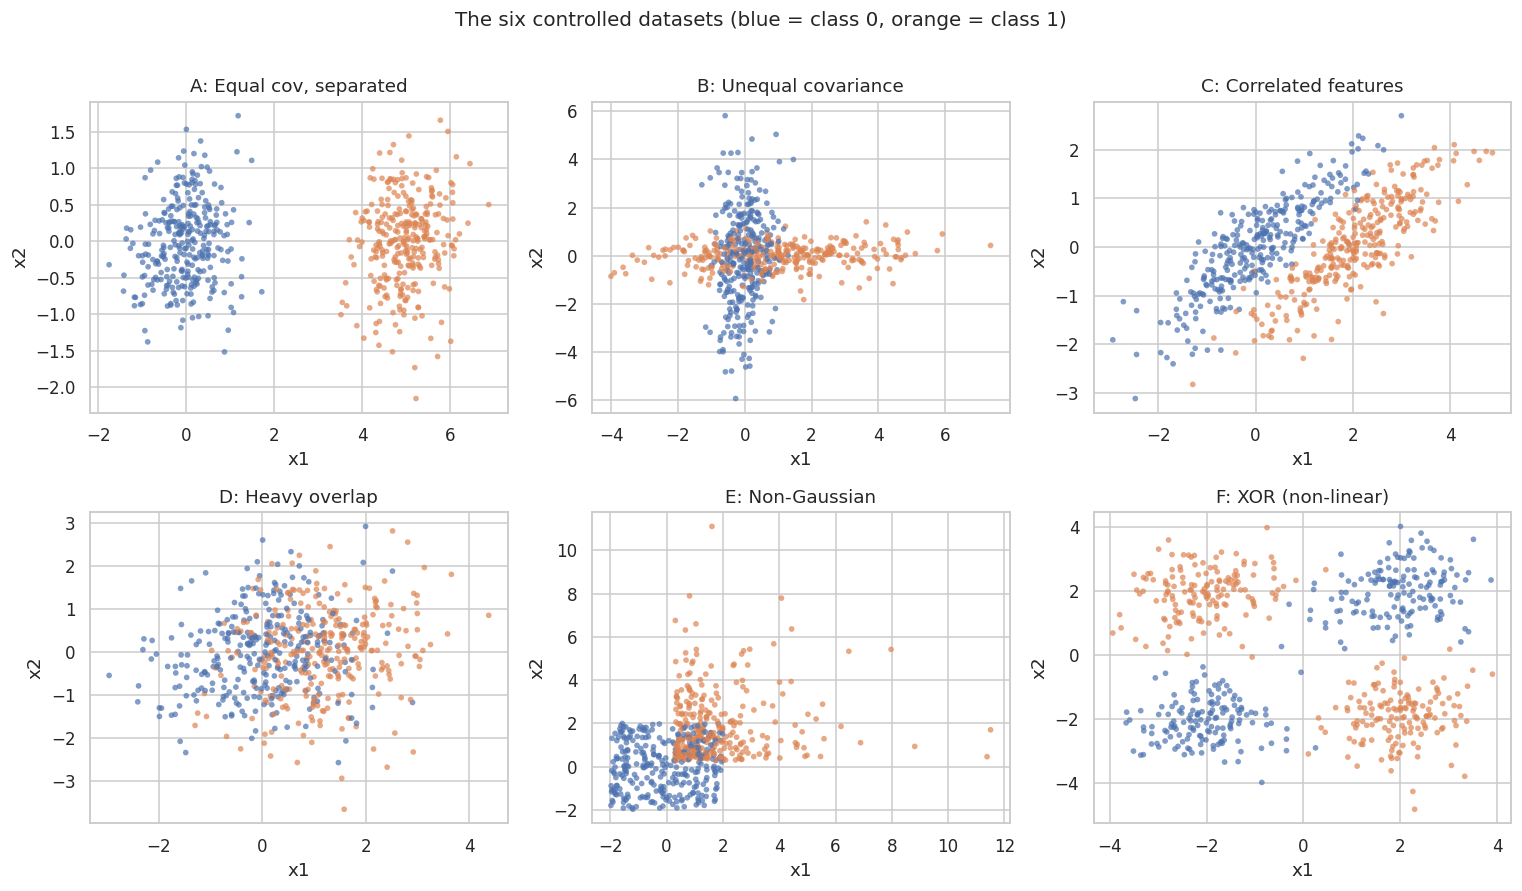

In [ ]:
def gauss2(n, m0, m1, S0, S1, rng):
    # Two-class Gaussian data, shuffled.
    n0 = n // 2
    X0 = rng.multivariate_normal(m0, S0, n0)
    X1 = rng.multivariate_normal(m1, S1, n - n0)
    X = np.vstack([X0, X1]); y = np.r_[np.zeros(n0, int), np.ones(n - n0, int)]
    idx = rng.permutation(n)
    return X[idx], y[idx]

def sc_A(n, rng, sep=5.0):                      # equal tight spherical covariance, far apart -> linearly separable
    return gauss2(n, [0, 0], [sep, 0], 0.35 * np.eye(2), 0.35 * np.eye(2), rng)

def sc_B(n, rng, sep=1.0, scale=4.0):           # unequal covariances -> quadratic boundary
    return gauss2(n, [0, 0], [sep, 0], np.diag([1/scale, scale]), np.diag([scale, 1/scale]), rng)

def sc_C(n, rng, sep=2.0, rho=0.85):            # shared covariance with strong correlation
    S = np.array([[1, rho], [rho, 1]])
    return gauss2(n, [0, 0], [sep, 0], S, S, rng)

def sc_D(n, rng, sep=1.2):                      # heavy overlap, equal covariance
    return gauss2(n, [0, 0], [sep, 0], np.eye(2), np.eye(2), rng)

def sc_E(n, rng, scale=1.5):                    # non-Gaussian: uniform vs skewed exponential
    n0 = n // 2
    X0 = rng.uniform(-2, 2, (n0, 2))
    X1 = rng.exponential(scale, (n - n0, 2)) + np.array([0.3, 0.3])
    X = np.vstack([X0, X1]); y = np.r_[np.zeros(n0, int), np.ones(n - n0, int)]
    idx = rng.permutation(n)
    return X[idx], y[idx]

def sc_F(n, rng, sep=2.0):                      # XOR: four blobs
    n0 = n // 2
    S = np.eye(2) * 0.6
    h0, h1 = n0 // 2, n - n0 - (n - n0) // 2
    X0 = np.vstack([rng.multivariate_normal([-sep, -sep], S, h0), rng.multivariate_normal([sep, sep], S, n0 - h0)])
    X1 = np.vstack([rng.multivariate_normal([-sep, sep], S, h1), rng.multivariate_normal([sep, -sep], S, (n - n0) - h1)])
    X = np.vstack([X0, X1]); y = np.r_[np.zeros(n0, int), np.ones(n - n0, int)]
    idx = rng.permutation(n)
    return X[idx], y[idx]

SCENARIOS = {
    "A: Equal cov, separated":   sc_A,
    "B: Unequal covariance":     sc_B,
    "C: Correlated features":    sc_C,
    "D: Heavy overlap":          sc_D,
    "E: Non-Gaussian":           sc_E,
    "F: XOR (non-linear)":       sc_F,
}

# Quick look at all six
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, (name, fn) in zip(axes.ravel(), SCENARIOS.items()):
    X, y = fn(N_SAMPLES, np.random.default_rng(SEED))
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=CMAP, s=14, alpha=0.7, edgecolor="none")
    ax.set_title(name); ax.set_xlabel("x1"); ax.set_ylabel("x2")
plt.suptitle("The six controlled datasets (blue = class 0, orange = class 1)", y=1.01, fontsize=13)
plt.tight_layout(); plt.show()

## 4. Validation of the from-scratch Bayes code
Before trusting our results we check the implementation against scikit-learn (`GaussianNB`, `QuadraticDiscriminantAnalysis`). Agreement should be very close to 100 %.

In [ ]:
rows = []
for name, fn in SCENARIOS.items():
    X, y = fn(N_SAMPLES, np.random.default_rng(SEED))
    ours_nb = GaussianBayes(naive=True).fit(X, y).predict(X)
    ours_fc = GaussianBayes(naive=False).fit(X, y).predict(X)
    sk_nb = GaussianNB(var_smoothing=1e-9).fit(X, y).predict(X)
    sk_fc = QuadraticDiscriminantAnalysis(reg_param=0.0).fit(X, y).predict(X)
    rows.append({"Scenario": name,
                 "Naive Bayes agreement with sklearn (%)": 100 * np.mean(ours_nb == sk_nb),
                 "Full-cov Bayes agreement with sklearn (%)": 100 * np.mean(ours_fc == sk_fc)})
val_df = pd.DataFrame(rows).set_index("Scenario").round(2)
display(val_df)

,Naive Bayes agreement with sklearn (%),Full-cov Bayes agreement with sklearn (%)
Scenario,,
"A: Equal cov, separated",100.0,100.0
B: Unequal covariance,100.0,100.0
C: Correlated features,100.0,100.0
D: Heavy overlap,100.0,100.0
E: Non-Gaussian,100.0,100.0
F: XOR (non-linear),100.0,100.0


## 5. Feature distribution analysis
This is the **"effect of feature distributions"** part of the problem. For each scenario (n = 2000) we measure the properties that matter to each classifier:

* **Skewness / excess kurtosis** – both are 0 for a Gaussian. Large values mean the Gaussian assumption of Bayes is violated.
* **Shapiro–Wilk p-value** – p < 0.05 means "not normal".
* **Cohen's d** – how far apart the class means are, per feature (bigger = easier).
* **Within-class correlation** – if far from 0, Naive Bayes' independence assumption is violated.
* **Variance ratio (class 1 / class 0), per feature** – far from 1 means the classes have different spreads along that axis, so the true boundary is curved.

,Cohen d (x1),Cohen d (x2),corr class0,corr class1,var ratio x1 (c1/c0),var ratio x2 (c1/c0),mean |skew|,% features non-normal
"A: Equal cov, separated",8.602,0.056,0.057,0.020,1.007,0.973,0.078,0.0
B: Unequal covariance,0.723,0.105,0.057,0.020,15.430,0.063,0.078,0.0
C: Correlated features,1.895,0.068,0.844,0.849,0.985,1.025,0.058,0.0
D: Heavy overlap,1.296,0.056,0.057,0.020,1.007,0.973,0.078,0.0
E: Non-Gaussian,1.364,1.296,0.040,0.037,1.288,1.843,1.012,100.0
F: XOR (non-linear),0.031,0.020,0.875,-0.867,1.023,1.005,0.010,100.0


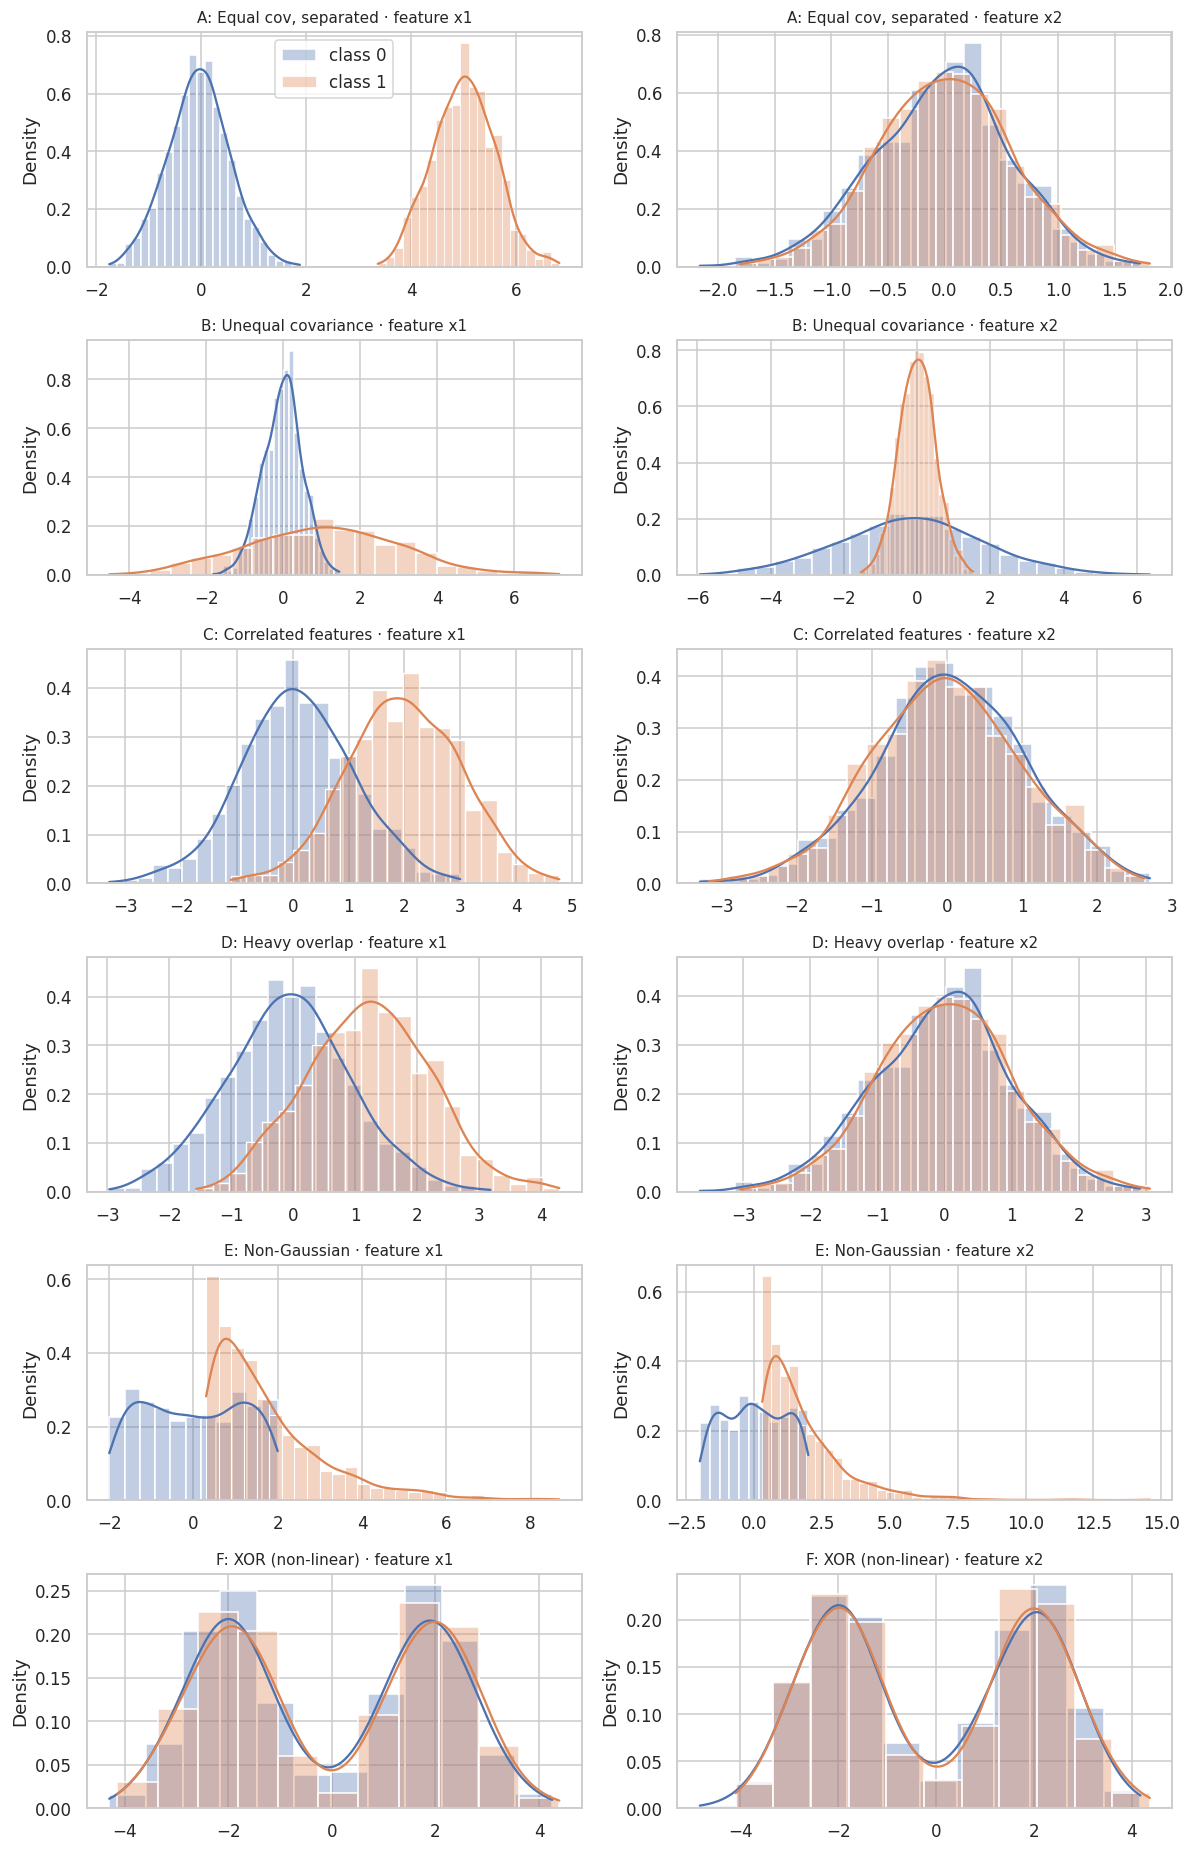

In [ ]:
def feature_report(X, y):
    rows = []
    X0, X1 = X[y == 0], X[y == 1]
    rng = np.random.default_rng(0)
    for j in range(X.shape[1]):
        for c, Xc in [(0, X0), (1, X1)]:
            sub = Xc[rng.choice(len(Xc), min(len(Xc), 500), replace=False), j]
            rows.append({"feature": f"x{j+1}", "class": c, "mean": Xc[:, j].mean(), "std": Xc[:, j].std(),
                         "skew": stats.skew(Xc[:, j]), "excess kurtosis": stats.kurtosis(Xc[:, j]),
                         "Shapiro p": stats.shapiro(sub)[1]})
    per_feat = pd.DataFrame(rows)
    pooled = np.sqrt((X0.var(axis=0) + X1.var(axis=0)) / 2)
    d = np.abs(X1.mean(axis=0) - X0.mean(axis=0)) / pooled
    summary = {
        "Cohen d (x1)": d[0], "Cohen d (x2)": d[1],
        "corr class0": np.corrcoef(X0.T)[0, 1], "corr class1": np.corrcoef(X1.T)[0, 1],
        "var ratio x1 (c1/c0)": X1[:, 0].var() / X0[:, 0].var(),
        "var ratio x2 (c1/c0)": X1[:, 1].var() / X0[:, 1].var(),
        "mean |skew|": per_feat["skew"].abs().mean(),
        "% features non-normal": 100 * (per_feat["Shapiro p"] < 0.05).mean(),
    }
    return per_feat, summary

summary_rows, big_data = {}, {}
for name, fn in SCENARIOS.items():
    X, y = fn(2000, np.random.default_rng(SEED))
    big_data[name] = (X, y)
    _, summary_rows[name] = feature_report(X, y)
dist_df = pd.DataFrame(summary_rows).T.round(3)
display(dist_df)

# Visual: class-conditional histograms of each feature
fig, axes = plt.subplots(6, 2, figsize=(11, 17))
for r, (name, (X, y)) in enumerate(big_data.items()):
    for j in range(2):
        ax = axes[r, j]
        for c, col in zip([0, 1], ["#4C72B0", "#DD8452"]):
            sns.histplot(X[y == c, j], kde=True, stat="density", color=col, alpha=0.35, ax=ax, label=f"class {c}")
        ax.set_title(f"{name} · feature x{j+1}", fontsize=10); ax.set_xlabel("")
        if r == 0 and j == 0: ax.legend()
plt.tight_layout(); plt.show()

**How to read the table.**
Scenario C has within-class correlation ≈ 0.85 → Naive Bayes is working with a wrong assumption.
Scenario B has variance ratios far from 1 (and opposite in x1 and x2) → the classes have very different shapes, so a straight line cannot be optimal.
Scenario E has clearly non-zero skewness and 100 % non-normal features → Gaussian densities fit badly. Scenario F shows 100 % non-normal because each class is a two-blob mixture, and its opposite-sign class correlations (+0.87 / −0.87) hint at why a full-covariance model can still capture it.
Scenario D has a small Cohen's d → classes overlap heavily, so some error is unavoidable for every model.

## 6. Main experiment
For each scenario and each of 10 random seeds: generate data → stratified 70/30 split → train all three models → record accuracy and macro-F1. Results are reported as **mean ± std over seeds**.

Test accuracy (%), mean ± std over 10 seeds


,Gaussian Naive Bayes,Gaussian Bayes (full cov),Perceptron
scenario,,,
"A: Equal cov, separated",100.0 ± 0.0,100.0 ± 0.0,99.8 ± 0.3
B: Unequal covariance,85.1 ± 3.7,85.2 ± 3.8,53.6 ± 10.3
C: Correlated features,83.9 ± 2.7,97.3 ± 0.7,95.6 ± 1.6
D: Heavy overlap,71.9 ± 3.6,71.9 ± 3.7,61.7 ± 12.0
E: Non-Gaussian,82.6 ± 1.8,82.4 ± 2.0,82.3 ± 2.5
F: XOR (non-linear),47.4 ± 3.8,99.3 ± 0.7,56.2 ± 10.9



Perceptron convergence (max 100 epochs)


,converged_runs,mean_epochs
scenario,,
"A: Equal cov, separated",10/10,2.0
B: Unequal covariance,0/10,100.0
C: Correlated features,0/10,100.0
D: Heavy overlap,0/10,100.0
E: Non-Gaussian,0/10,100.0
F: XOR (non-linear),0/10,100.0


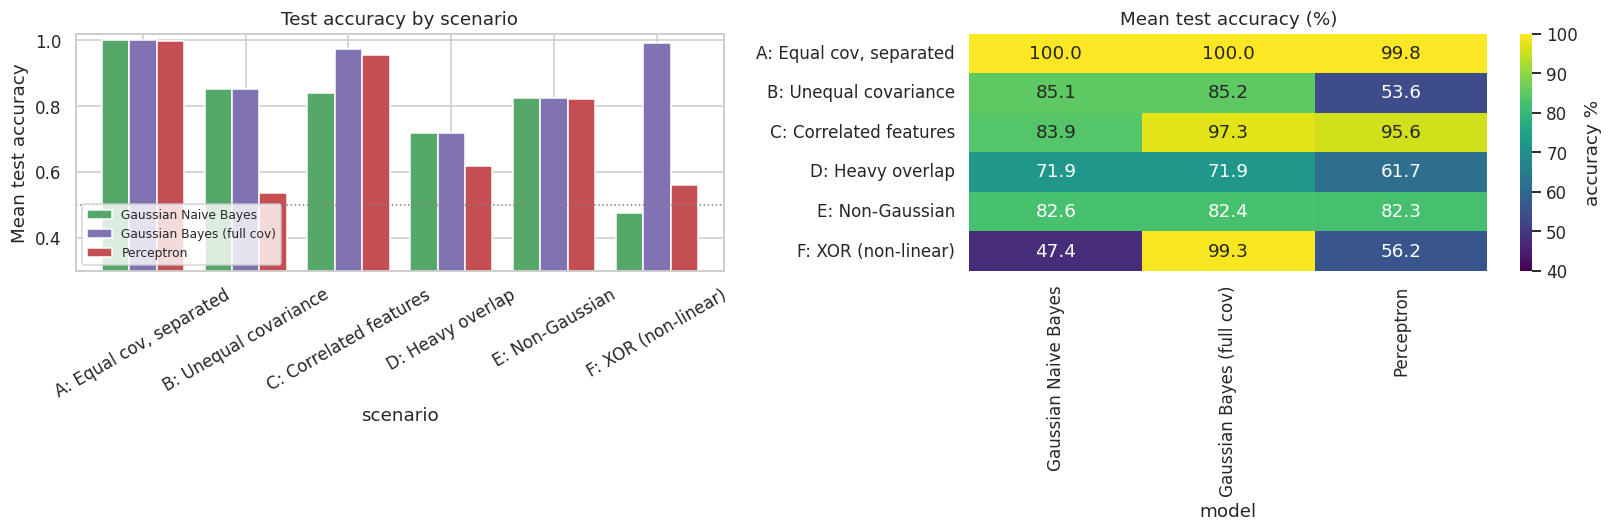

In [ ]:
def split(X, y, seed, test_size=0.3):
    return train_test_split(X, y, test_size=test_size, stratify=y, random_state=seed)

def fit_eval(X_tr, y_tr, X_te, y_te, seed=0):
    out, fitted = {}, {}
    for mname, make in MODELS.items():
        m = make()
        if isinstance(m, PerceptronScratch): m.seed = seed
        m.fit(X_tr, y_tr)
        pred = m.predict(X_te)
        out[mname] = {"train_acc": accuracy_score(y_tr, m.predict(X_tr)),
                      "test_acc": accuracy_score(y_te, pred),
                      "test_f1": f1_score(y_te, pred, average="macro")}
        fitted[mname] = m
    return out, fitted

records, perc_info = [], []
for sname, fn in SCENARIOS.items():
    for s in range(N_SEEDS):
        X, y = fn(N_SAMPLES, np.random.default_rng(1000 + s))
        X_tr, X_te, y_tr, y_te = split(X, y, 1000 + s)
        res, fitted = fit_eval(X_tr, y_tr, X_te, y_te, seed=s)
        for mname, r in res.items():
            records.append({"scenario": sname, "seed": s, "model": mname, **r})
        p = fitted["Perceptron"]
        perc_info.append({"scenario": sname, "seed": s, "epochs_used": len(p.errors_), "converged": p.converged_})

results_df = pd.DataFrame(records)
perc_df = pd.DataFrame(perc_info)

agg = results_df.groupby(["scenario", "model"])[["test_acc", "test_f1"]].agg(["mean", "std"])
table = pd.DataFrame({
    m: results_df[results_df.model == m].groupby("scenario")["test_acc"].apply(lambda s: f"{100*s.mean():.1f} ± {100*s.std():.1f}")
    for m in MODELS})
print("Test accuracy (%), mean ± std over", N_SEEDS, "seeds")
display(table)

conv = perc_df.groupby("scenario").agg(converged_runs=("converged", "sum"), mean_epochs=("epochs_used", "mean"))
conv["converged_runs"] = conv["converged_runs"].astype(int).astype(str) + f"/{N_SEEDS}"
print("\nPerceptron convergence (max 100 epochs)")
display(conv.round(1))

# Figures
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
mean_acc = results_df.pivot_table(index="scenario", columns="model", values="test_acc", aggfunc="mean")[list(MODELS)]
mean_acc.plot(kind="bar", ax=axes[0], color=[MODEL_COLORS[m] for m in MODELS], width=0.8)
axes[0].set_ylabel("Mean test accuracy"); axes[0].set_ylim(0.3, 1.02); axes[0].axhline(0.5, color="gray", ls=":", lw=1)
axes[0].set_title("Test accuracy by scenario"); axes[0].tick_params(axis="x", rotation=30)
axes[0].legend(fontsize=8, loc="lower left")
sns.heatmap(100 * mean_acc, annot=True, fmt=".1f", cmap="viridis", vmin=40, vmax=100, ax=axes[1], cbar_kws={"label": "accuracy %"})
axes[1].set_title("Mean test accuracy (%)"); axes[1].set_ylabel("")
plt.tight_layout(); plt.show()

## 7. Decision boundaries
Shaded regions show what each model predicts at every point of the plane; dots are the **test** samples.
Look at the *shape* of each boundary: perceptron = always a straight line, Naive Bayes = curved but built from independent axes, full-covariance Bayes = curved and can tilt to follow correlations.

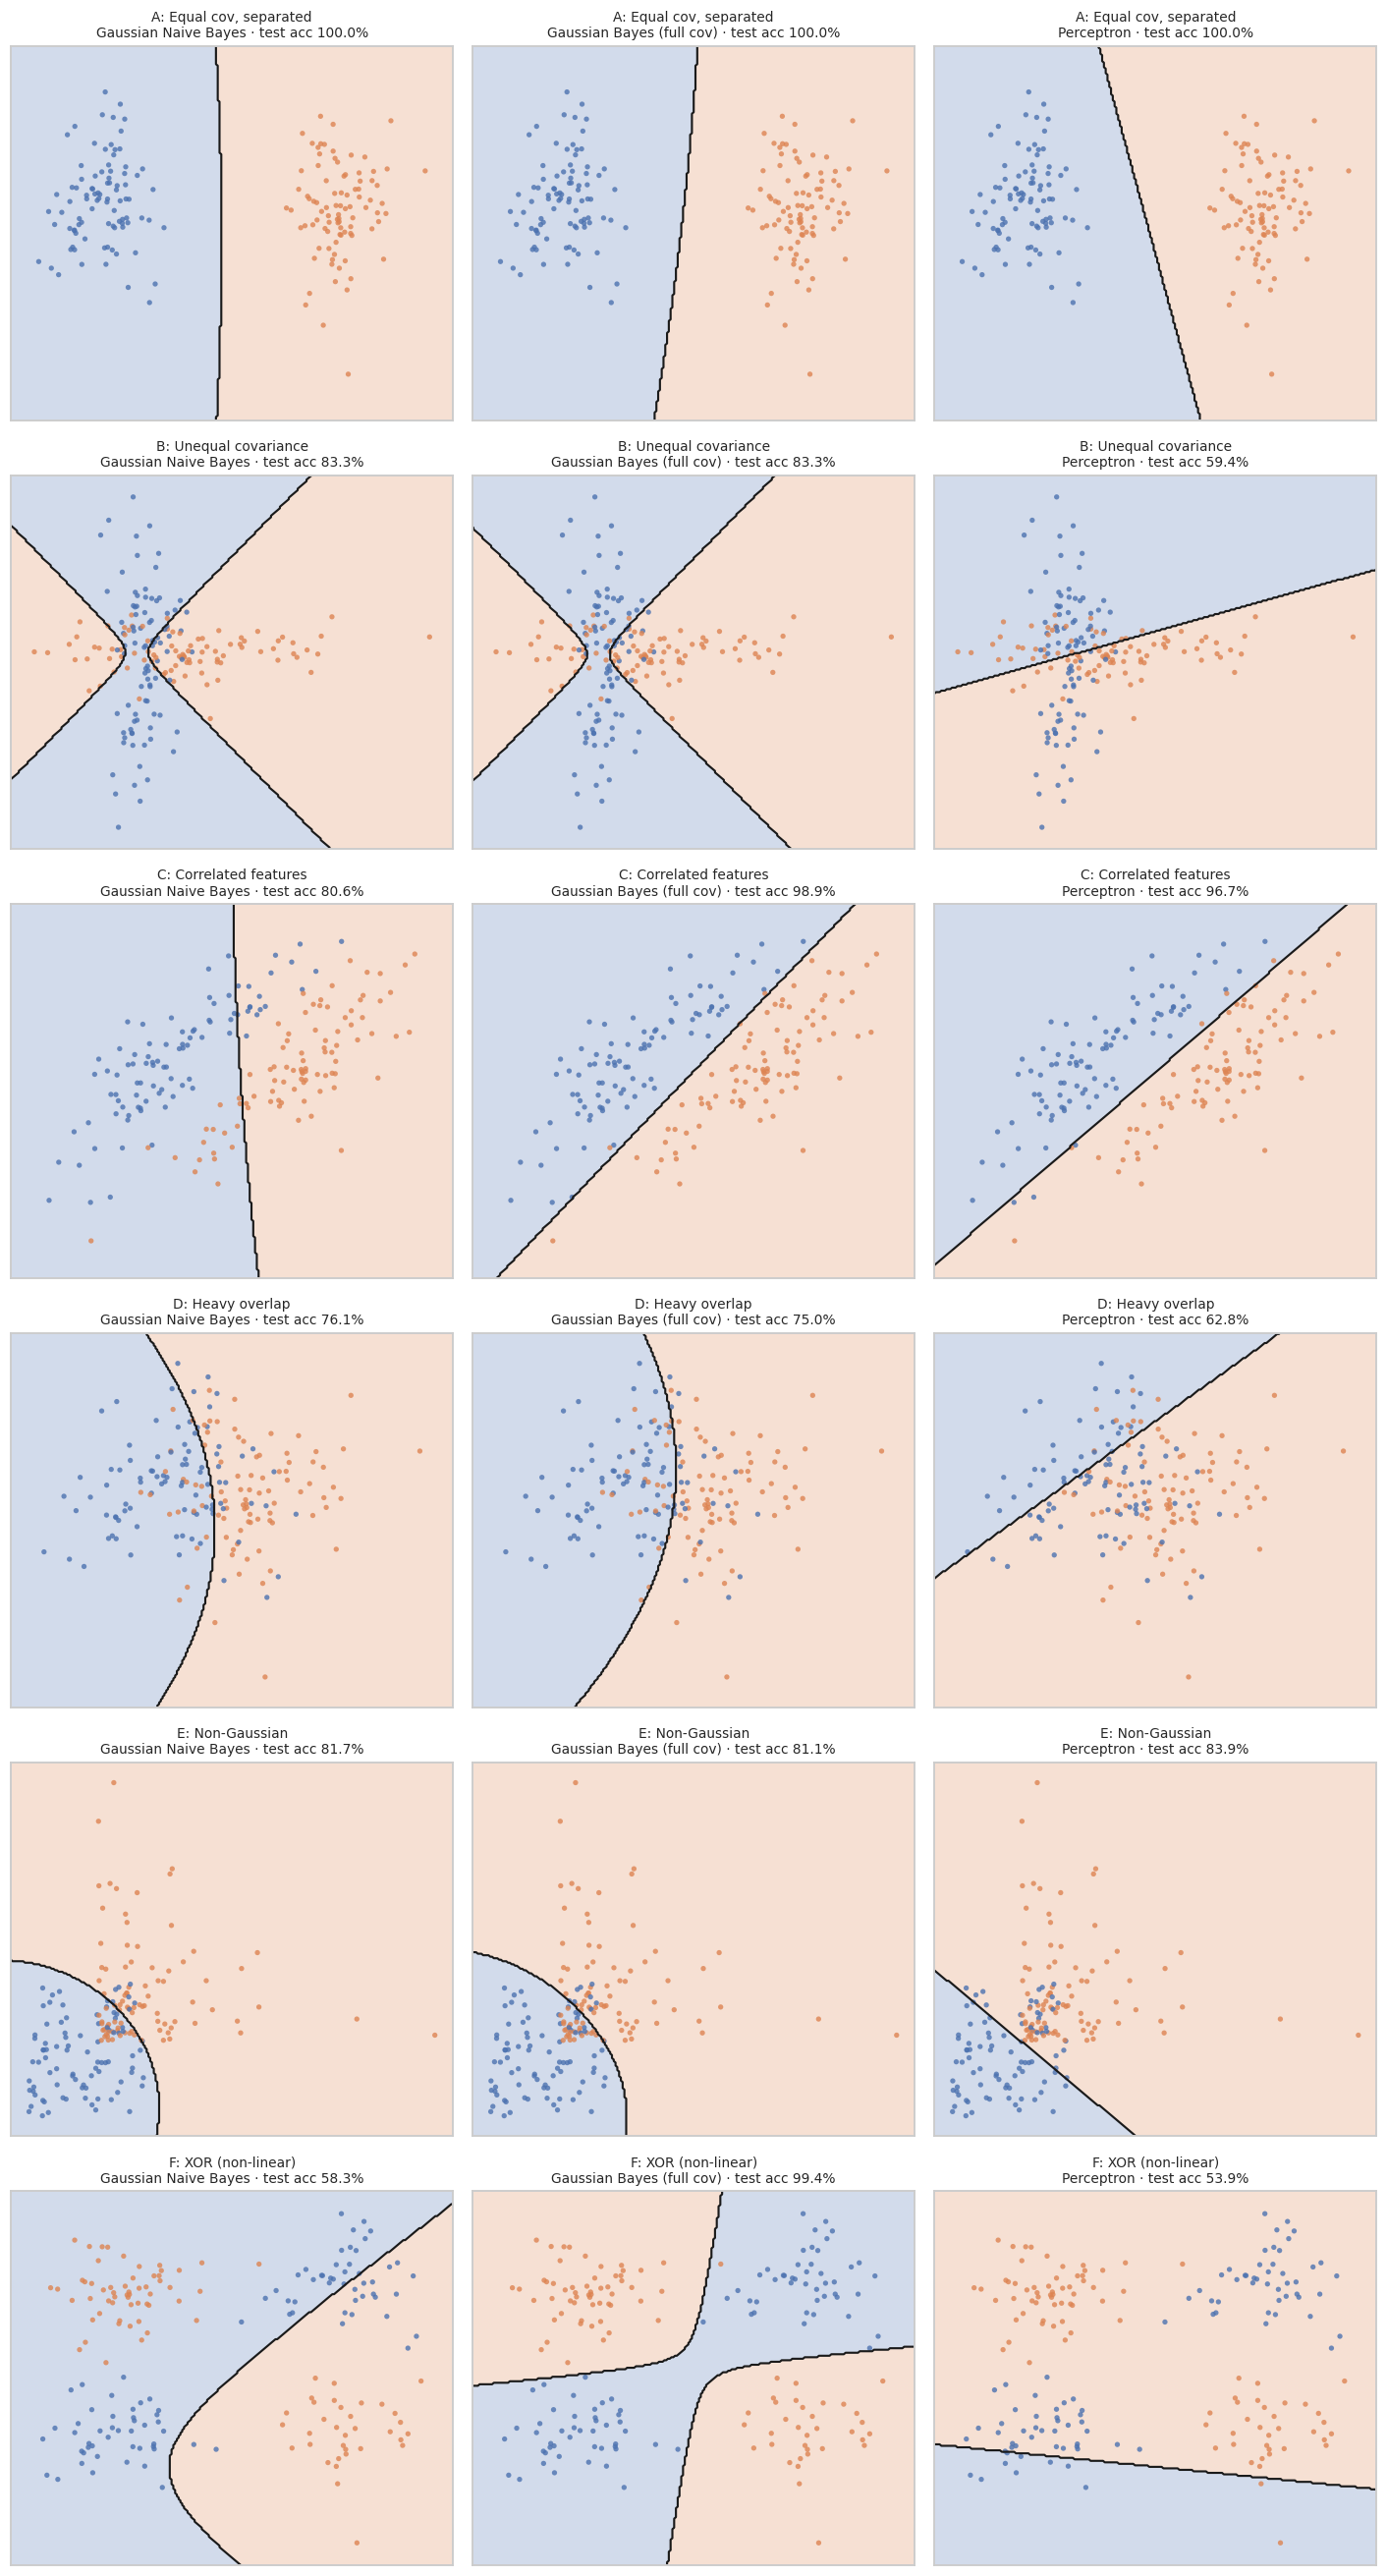

In [ ]:
def plot_boundary(ax, model, X, y, title, pad=0.6):
    x_min, x_max = X[:, 0].min() - pad, X[:, 0].max() + pad
    y_min, y_max = X[:, 1].min() - pad, X[:, 1].max() + pad
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 250), np.linspace(y_min, y_max, 250))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], cmap=CMAP, alpha=0.25)
    ax.contour(xx, yy, Z, levels=[0.5], colors="k", linewidths=1.4)
    ax.scatter(X[:, 0], X[:, 1], c=y, cmap=CMAP, s=12, edgecolor="none", alpha=0.8)
    ax.set_title(title, fontsize=9); ax.set_xticks([]); ax.set_yticks([])

demo = {}   # keep fitted models and splits for confusion matrices
fig, axes = plt.subplots(len(SCENARIOS), 3, figsize=(13, 4.0 * len(SCENARIOS)))
for r, (sname, fn) in enumerate(SCENARIOS.items()):
    X, y = fn(N_SAMPLES, np.random.default_rng(SEED))
    X_tr, X_te, y_tr, y_te = split(X, y, SEED)
    res, fitted = fit_eval(X_tr, y_tr, X_te, y_te, seed=SEED)
    demo[sname] = (fitted, X_te, y_te)
    for c, mname in enumerate(MODELS):
        plot_boundary(axes[r, c], fitted[mname], X_te, y_te, f"{sname}\n{mname} · test acc {100*res[mname]['test_acc']:.1f}%")
plt.tight_layout(); plt.show()

## 8. Confusion matrices
Rows = true class, columns = predicted class (counts on the test set, same split as the boundary plots above).

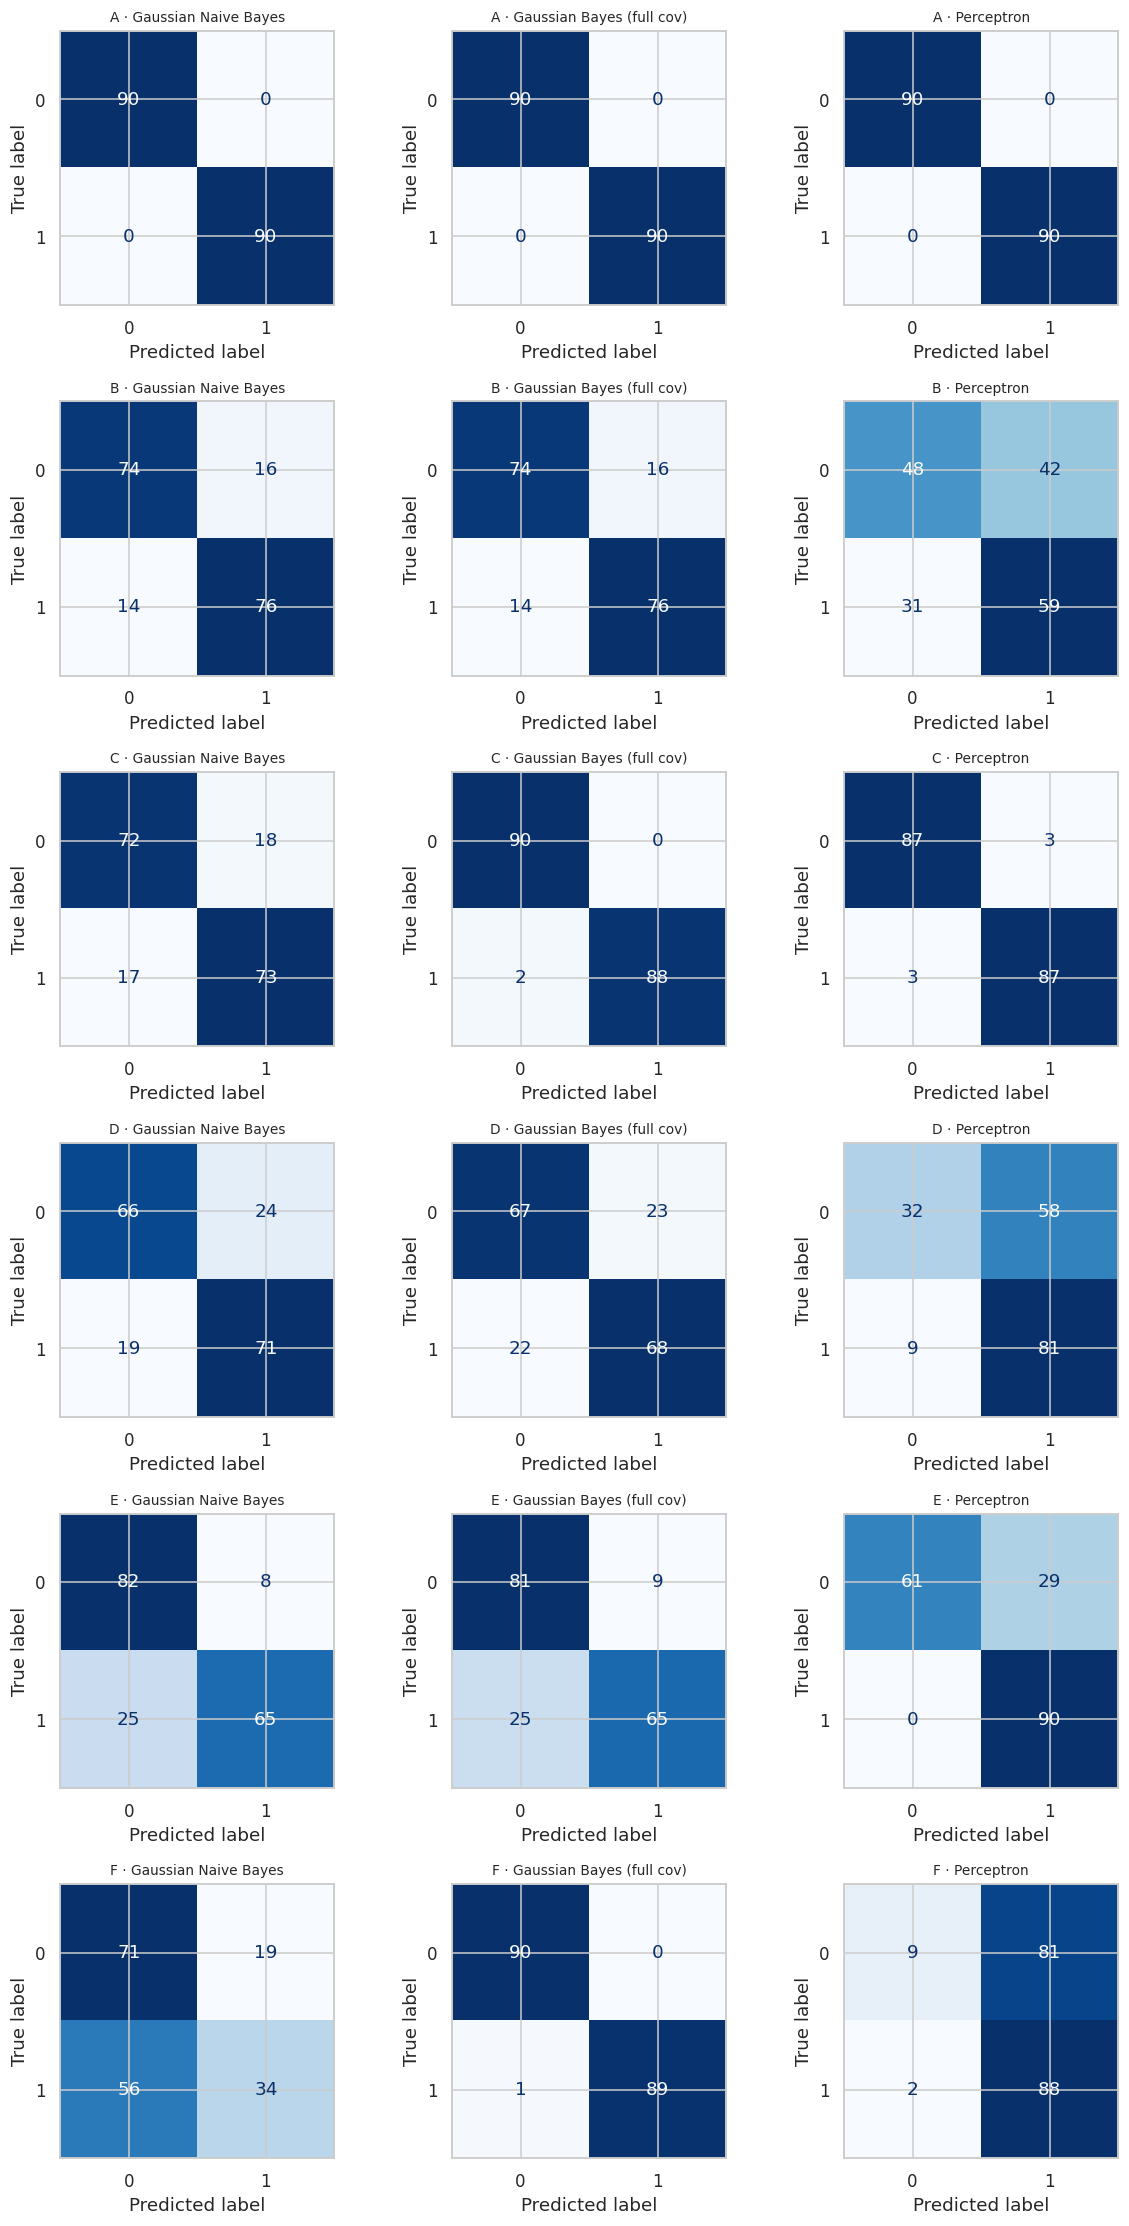

In [ ]:
fig, axes = plt.subplots(len(SCENARIOS), 3, figsize=(11, 3.4 * len(SCENARIOS)))
for r, (sname, (fitted, X_te, y_te)) in enumerate(demo.items()):
    for c, mname in enumerate(MODELS):
        cm = confusion_matrix(y_te, fitted[mname].predict(X_te))
        ConfusionMatrixDisplay(cm, display_labels=["0", "1"]).plot(ax=axes[r, c], cmap="Blues", colorbar=False)
        axes[r, c].set_title(f"{sname[:1]} · {mname}", fontsize=9)
plt.tight_layout(); plt.show()

## 9. Controlled sweeps: changing one knob at a time
Each curve is the **mean over 10 seeds** and the band is ±1 standard deviation.

1. **Class separation** (how far apart the means are) with equal covariance.
2. **Feature correlation** ρ (tests Naive Bayes' independence assumption).
3. **Covariance mismatch** (how different the two class shapes are, tests linear vs curved boundaries).
4. **Training-set size** (generative vs discriminative sample efficiency).

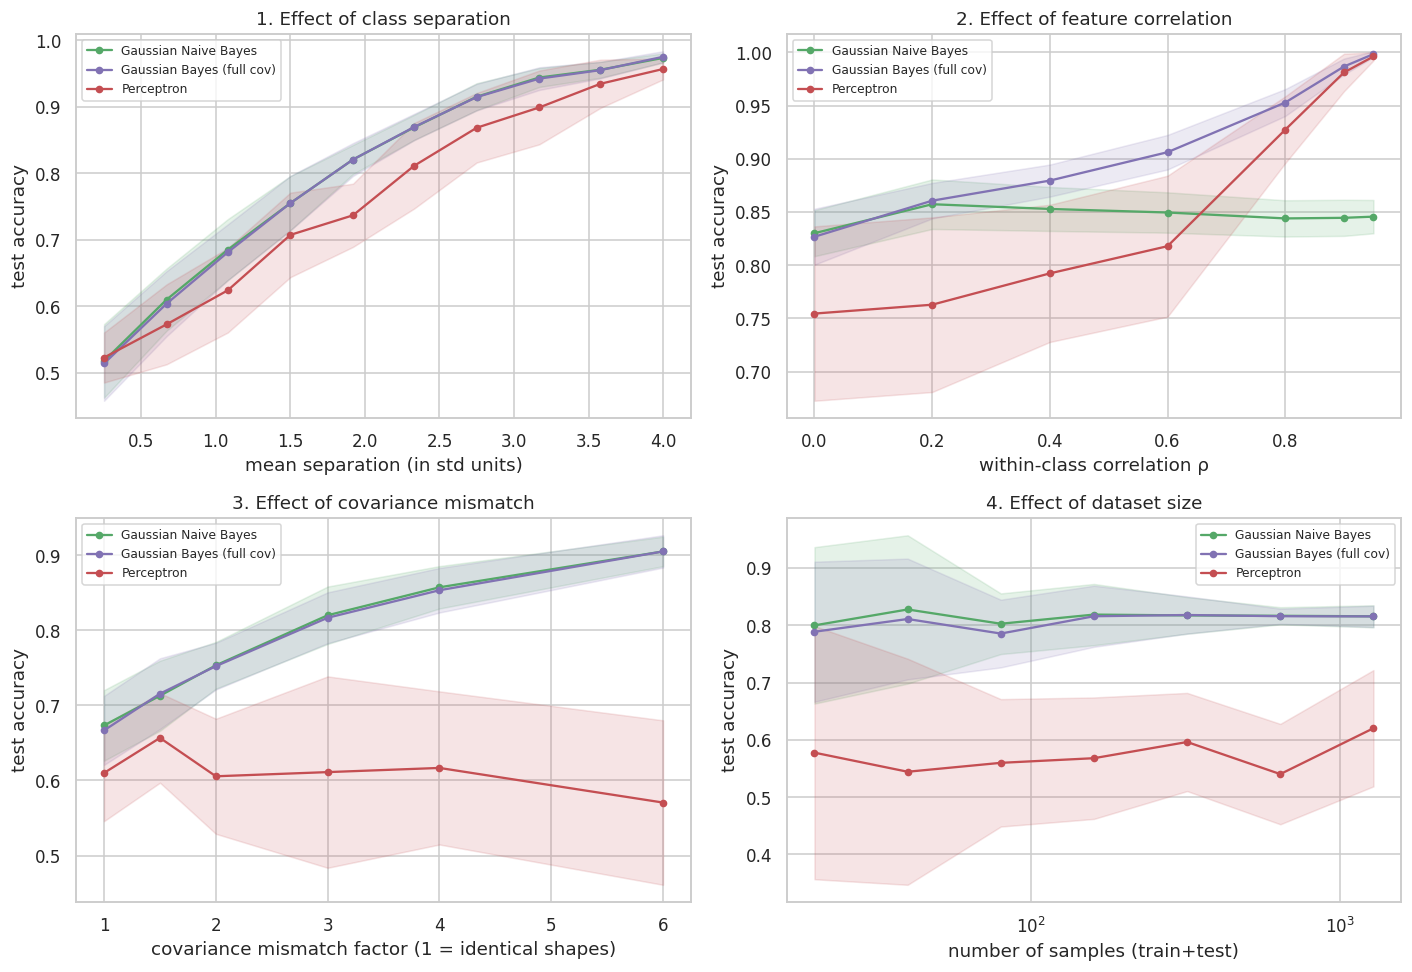


Mean test accuracy (%) - sweep: Separation


model,Gaussian Naive Bayes,Gaussian Bayes (full cov),Perceptron
value,,,
0.25,51.8,51.4,52.3
0.67,61.0,60.4,57.3
1.08,68.5,68.1,62.4
1.50,75.5,75.5,70.7
1.92,82.1,82.1,73.7
2.33,86.9,86.9,81.1
2.75,91.5,91.4,86.8
3.17,94.4,94.2,89.9
3.58,95.6,95.5,93.4



Mean test accuracy (%) - sweep: Correlation rho


model,Gaussian Naive Bayes,Gaussian Bayes (full cov),Perceptron
value,,,
0.00,83.0,82.7,75.4
0.20,85.7,86.1,76.3
0.40,85.3,87.9,79.2
0.60,84.9,90.6,81.8
0.80,84.4,95.3,92.7
0.90,84.4,98.7,98.1
0.95,84.6,99.8,99.6



Mean test accuracy (%) - sweep: Covariance mismatch


model,Gaussian Naive Bayes,Gaussian Bayes (full cov),Perceptron
value,,,
1.0,67.3,66.7,61.0
1.5,71.3,71.6,65.7
2.0,75.3,75.2,60.6
3.0,82.0,81.7,61.1
4.0,85.7,85.3,61.7
6.0,90.5,90.5,57.1



Mean test accuracy (%) - sweep: Dataset size


model,Gaussian Naive Bayes,Gaussian Bayes (full cov),Perceptron
value,,,
20,80.0,78.9,57.8
40,82.8,81.1,54.4
80,80.3,78.6,56.0
160,81.9,81.6,56.8
320,81.7,81.8,59.6
640,81.7,81.6,54.0
1280,81.6,81.6,62.0


In [ ]:
def run_sweep(values, make_data, n_seeds=N_SEEDS, test_n=1000):
    # make_data(value, n, rng) -> X, y.  Fixed test-set size so training size can be varied too.
    rows = []
    for v in values:
        for s in range(n_seeds):
            rng = np.random.default_rng(5000 + s)
            X, y = make_data(v, rng)
            X_tr, X_te, y_tr, y_te = split(X, y, 5000 + s)
            res, _ = fit_eval(X_tr, y_tr, X_te, y_te, seed=s)
            for m, r in res.items():
                rows.append({"value": v, "seed": s, "model": m, "test_acc": r["test_acc"]})
    return pd.DataFrame(rows)

def plot_sweep(df, ax, xlabel, title, logx=False):
    for m in MODELS:
        sub = df[df.model == m]
        g = sub.groupby("value")["test_acc"].agg(["mean", "std"]).reset_index()
        ax.plot(g["value"], g["mean"], marker="o", ms=4, label=m, color=MODEL_COLORS[m])
        ax.fill_between(g["value"], g["mean"] - g["std"], g["mean"] + g["std"], color=MODEL_COLORS[m], alpha=0.15)
    ax.set_xlabel(xlabel); ax.set_ylabel("test accuracy"); ax.set_title(title)
    if logx: ax.set_xscale("log")
    ax.legend(fontsize=8)

# 1. separation (equal spherical covariance)
sweep_sep = run_sweep(np.round(np.linspace(0.25, 4.0, 10), 2), lambda v, rng: gauss2(N_SAMPLES, [0, 0], [v, 0], np.eye(2), np.eye(2), rng))
# 2. correlation (shared covariance, mean shift along x)
sweep_rho = run_sweep([0.0, 0.2, 0.4, 0.6, 0.8, 0.9, 0.95],
                      lambda v, rng: gauss2(N_SAMPLES, [0, 0], [2.0, 0], np.array([[1, v], [v, 1]]), np.array([[1, v], [v, 1]]), rng))
# 3. covariance mismatch (class-1 covariance diag(s, 1/s); class-0 covariance diag(1/s, s))
sweep_cov = run_sweep([1.0, 1.5, 2.0, 3.0, 4.0, 6.0],
                      lambda v, rng: gauss2(N_SAMPLES, [0, 0], [1.0, 0], np.diag([1/v, v]), np.diag([v, 1/v]), rng))
# 4. training-set size (scenario B-like data, fixed test size = 1000)
def make_size(v, rng):
    X, y = gauss2(int(v / 0.7) , [0, 0], [1.0, 0], np.diag([1/3, 3]), np.diag([3, 1/3]), rng)
    return X, y
sweep_n = run_sweep([20, 40, 80, 160, 320, 640, 1280], make_size)

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_sweep(sweep_sep, axes[0, 0], "mean separation (in std units)", "1. Effect of class separation")
plot_sweep(sweep_rho, axes[0, 1], "within-class correlation ρ", "2. Effect of feature correlation")
plot_sweep(sweep_cov, axes[1, 0], "covariance mismatch factor (1 = identical shapes)", "3. Effect of covariance mismatch")
plot_sweep(sweep_n, axes[1, 1], "number of samples (train+test)", "4. Effect of dataset size", logx=True)
plt.tight_layout(); plt.show()

for title, df_ in [("Separation", sweep_sep), ("Correlation rho", sweep_rho), ("Covariance mismatch", sweep_cov), ("Dataset size", sweep_n)]:
    print(f"\nMean test accuracy (%) - sweep: {title}")
    display((100 * df_.pivot_table(index="value", columns="model", values="test_acc", aggfunc="mean")[list(MODELS)]).round(1))

## 10. Perceptron convergence behaviour
Perceptron convergence theorem: **if** the data are linearly separable, the mistake count reaches zero in finite time. Here we plot mistakes per epoch for a separable scenario (A) and overlapping ones (C, D, F).

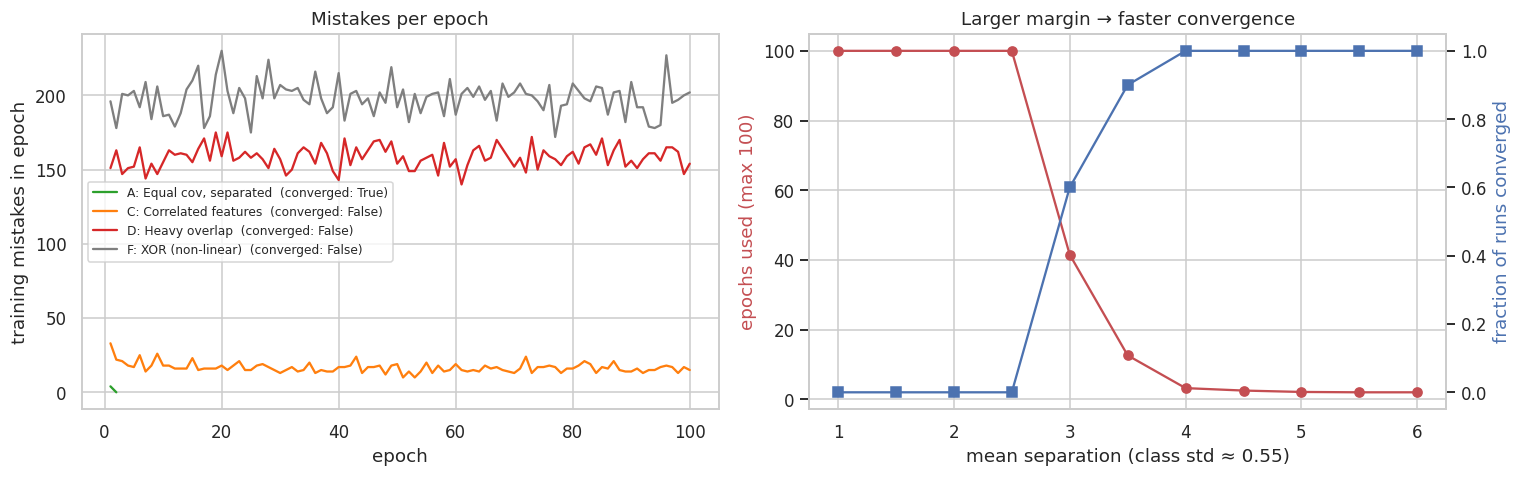

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for sname, col in zip(["A: Equal cov, separated", "C: Correlated features", "D: Heavy overlap", "F: XOR (non-linear)"],
                      ["#2ca02c", "#ff7f0e", "#d62728", "#7f7f7f"]):
    X, y = SCENARIOS[sname](N_SAMPLES, np.random.default_rng(SEED))
    X_tr, X_te, y_tr, y_te = split(X, y, SEED)
    p = PerceptronScratch(max_epochs=100, seed=SEED).fit(X_tr, y_tr)
    axes[0].plot(range(1, len(p.errors_) + 1), p.errors_, label=f"{sname}  (converged: {p.converged_})", color=col)
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("training mistakes in epoch"); axes[0].set_title("Mistakes per epoch")
axes[0].legend(fontsize=8)

# Effect of margin: epochs to converge vs separation
seps = np.round(np.linspace(1.0, 6.0, 11), 2)
mean_ep, conv_rate = [], []
for sp in seps:
    eps, cv = [], []
    for s in range(N_SEEDS):
        X, y = gauss2(N_SAMPLES, [0, 0], [sp, 0], np.eye(2) * 0.3, np.eye(2) * 0.3, np.random.default_rng(9000 + s))
        p = PerceptronScratch(max_epochs=100, seed=s).fit(X, y)
        eps.append(len(p.errors_)); cv.append(p.converged_)
    mean_ep.append(np.mean(eps)); conv_rate.append(np.mean(cv))
ax2 = axes[1]
ax2.plot(seps, mean_ep, marker="o", color="#C44E52", label="mean epochs used")
ax2.set_xlabel("mean separation (class std ≈ 0.55)"); ax2.set_ylabel("epochs used (max 100)", color="#C44E52")
ax3 = ax2.twinx(); ax3.plot(seps, conv_rate, marker="s", color="#4C72B0", label="fraction converged")
ax3.set_ylabel("fraction of runs converged", color="#4C72B0"); ax3.set_ylim(-0.05, 1.05); ax3.grid(False)
ax2.set_title("Larger margin → faster convergence")
plt.tight_layout(); plt.show()

## 11. Real datasets
Synthetic data are clean by design; here we check the same models on real data.

* **Iris** (versicolor vs virginica), loaded from a **public URL**, with an offline fallback if the URL is unreachable.
* **Breast Cancer Wisconsin** (30 features) from scikit-learn's built-in copy. With 30 features the full-covariance model must estimate 2 × 465 covariance terms, a good test of generative-model data hunger.

Iris loaded from URL: (100, 4)


,Gaussian Naive Bayes,Gaussian Bayes (full cov),Perceptron
Dataset,,,
Iris (4 features),94.7 ± 4.2,97.3 ± 3.1,94.0 ± 4.1
Iris (petal length+width only),95.0 ± 3.6,96.7 ± 3.1,90.3 ± 6.4
Breast Cancer (30 features),93.9 ± 1.5,95.6 ± 1.3,96.0 ± 2.2


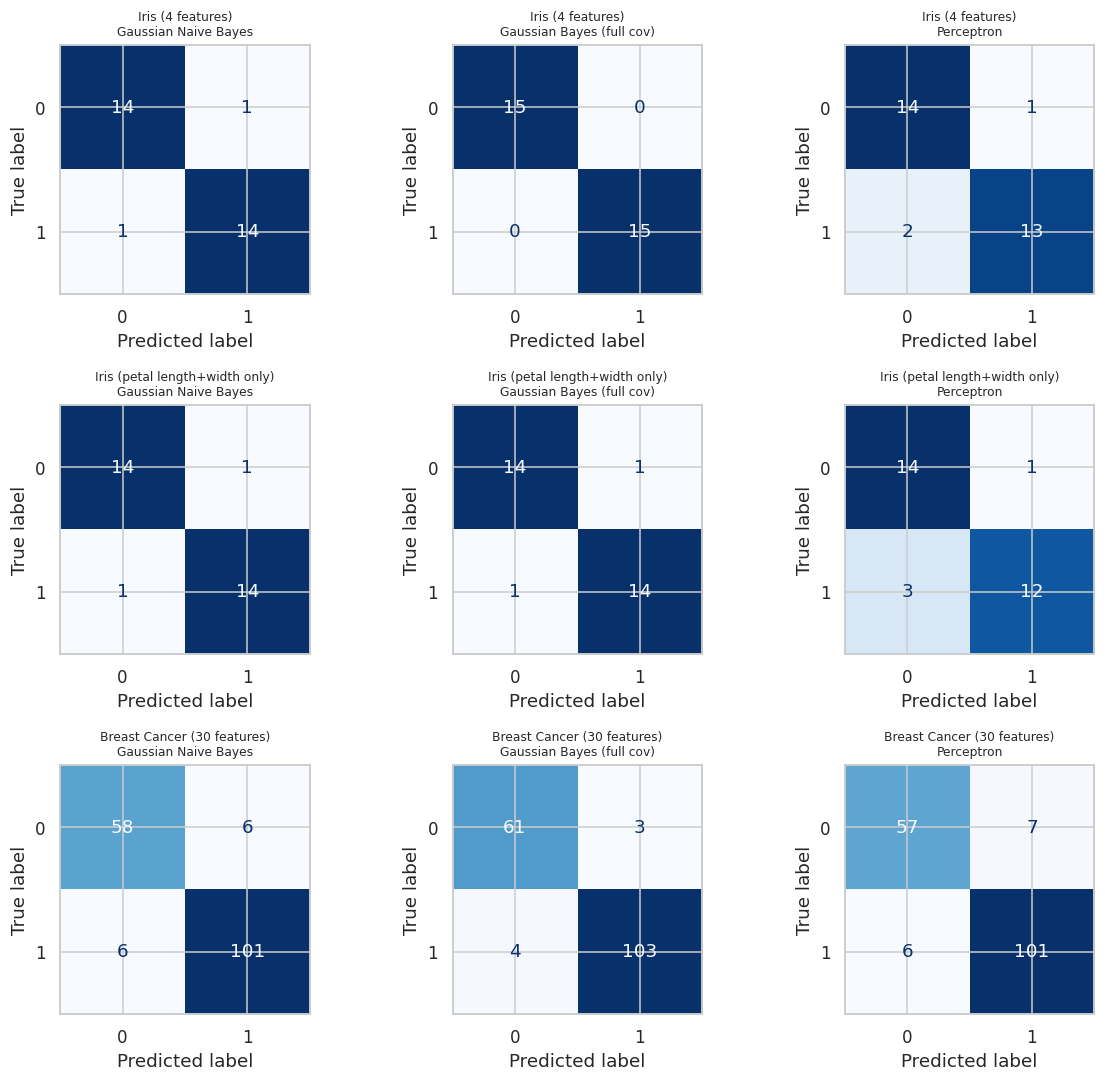

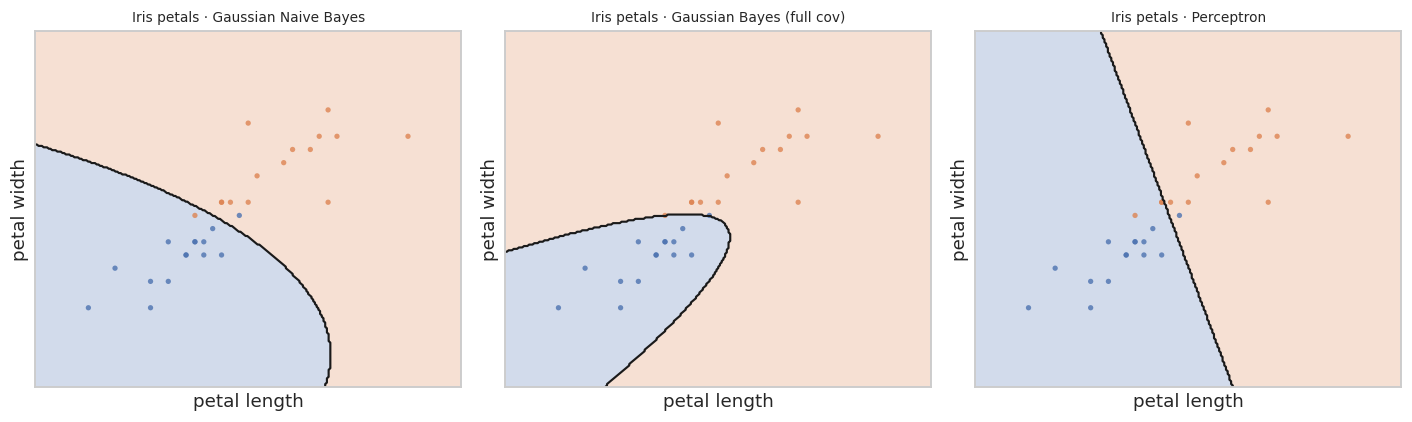

In [ ]:
IRIS_URL = "https://raw.githubusercontent.com/mwaskom/seaborn-data/master/iris.csv"
try:
    iris_df = pd.read_csv(IRIS_URL)
    iris_df = iris_df[iris_df["species"].isin(["versicolor", "virginica"])]
    X_iris = iris_df[["sepal_length", "sepal_width", "petal_length", "petal_width"]].values
    y_iris = (iris_df["species"] == "virginica").astype(int).values
    print("Iris loaded from URL:", X_iris.shape)
except Exception as e:
    print("URL not reachable (", type(e).__name__, ") -> using scikit-learn's built-in Iris")
    d = load_iris(); mask = d.target > 0
    X_iris, y_iris = d.data[mask], (d.target[mask] == 2).astype(int)

bc = load_breast_cancer()
real = {"Iris (4 features)": (X_iris, y_iris),
        "Iris (petal length+width only)": (X_iris[:, 2:], y_iris),
        "Breast Cancer (30 features)": (bc.data, bc.target)}

rows, real_fitted = [], {}
for dname, (X, y) in real.items():
    accs = {m: [] for m in MODELS}
    for s in range(N_SEEDS):
        X_tr, X_te, y_tr, y_te = split(X, y, 200 + s)
        res, fitted = fit_eval(X_tr, y_tr, X_te, y_te, seed=s)
        for m in MODELS: accs[m].append(res[m]["test_acc"])
        if s == 0: real_fitted[dname] = (fitted, X_te, y_te)
    rows.append({"Dataset": dname, **{m: f"{100*np.mean(v):.1f} ± {100*np.std(v, ddof=1):.1f}" for m, v in accs.items()}})
display(pd.DataFrame(rows).set_index("Dataset"))

# confusion matrices (seed 0 split) + 2-D boundary for the petal-only Iris
fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for r, (dname, (fitted, X_te, y_te)) in enumerate(real_fitted.items()):
    for c, m in enumerate(MODELS):
        ConfusionMatrixDisplay(confusion_matrix(y_te, fitted[m].predict(X_te))).plot(ax=axes[r, c], cmap="Blues", colorbar=False)
        axes[r, c].set_title(f"{dname}\n{m}", fontsize=8)
plt.tight_layout(); plt.show()

fitted, X_te, y_te = real_fitted["Iris (petal length+width only)"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, m in zip(axes, MODELS):
    plot_boundary(ax, fitted[m], X_te, y_te, f"Iris petals · {m}")
    ax.set_xlabel("petal length"); ax.set_ylabel("petal width"); ax.set_xticks(ax.get_xticks()[1:-1]); ax.set_yticks(ax.get_yticks()[1:-1])
plt.tight_layout(); plt.show()

## 12. Interactive experiment
Run the next cell and answer the prompts (press **Enter** to accept the default shown in brackets).
Try e.g. scenario **3** (correlated) and push the correlation up, or scenario **1** with a tiny separation.

Scenarios:
  1. A: Equal cov, separated
  2. B: Unequal covariance
  3. C: Correlated features
  4. D: Heavy overlap
  5. E: Non-Gaussian
  6. F: XOR (non-linear)
Choose scenario number (1-6) [default: 3]: 2
Number of samples (100-5000) [default: 600]: 468
Covariance mismatch factor (1-8) [default: 4.0]: 3

Scenario: B: Unequal covariance  | settings: {'scale': 3.0} | n = 468


,train_acc,test_acc,test_f1
Gaussian Naive Bayes,0.820,0.787,0.786
Gaussian Bayes (full cov),0.823,0.794,0.793
Perceptron,0.728,0.638,0.591


Perceptron converged: False after 100 epoch(s)


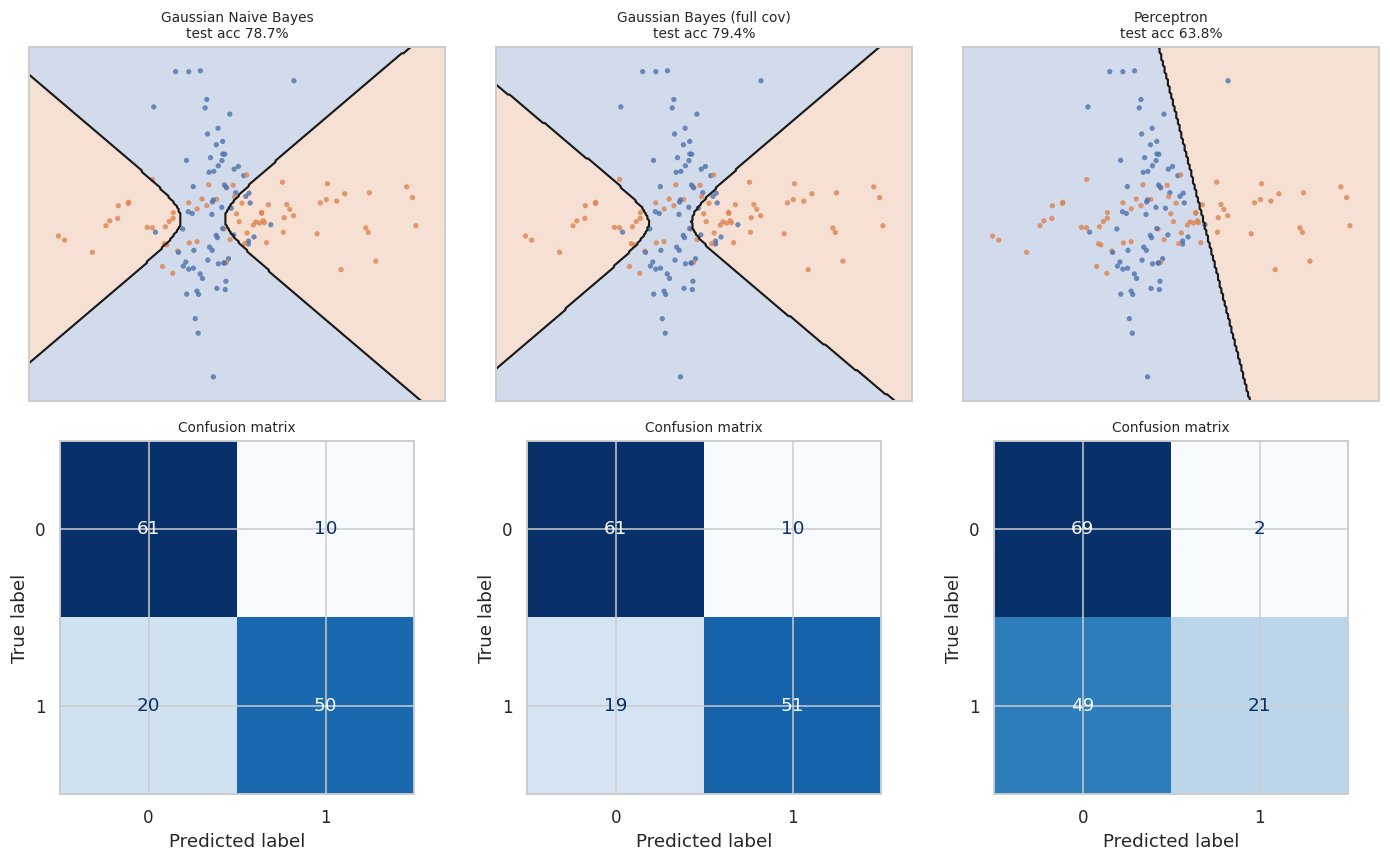

In [ ]:
def ask(prompt, default, cast=str, lo=None, hi=None):
    try:
        raw = input(f"{prompt} [default: {default}]: ").strip()
    except Exception:
        raw = ""
    if raw == "":
        return default
    try:
        val = cast(raw)
        if (lo is not None and val < lo) or (hi is not None and val > hi):
            raise ValueError
        return val
    except ValueError:
        print(f"  invalid input, using default {default}")
        return default

names = list(SCENARIOS)
print("Scenarios:")
for i, n in enumerate(names, 1): print(f"  {i}. {n}")
idx = ask("Choose scenario number (1-6)", 3, int, 1, 6)
n_pts = ask("Number of samples (100-5000)", 600, int, 100, 5000)
sname = names[idx - 1]

kwargs = {}
if sname.startswith(("A", "D", "F")):
    kwargs["sep"] = ask("Class separation (0.2-8)", {"A": 5.0, "D": 1.2, "F": 2.0}[sname[0]], float, 0.2, 8)
elif sname.startswith("B"):
    kwargs["scale"] = ask("Covariance mismatch factor (1-8)", 4.0, float, 1, 8)
elif sname.startswith("C"):
    kwargs["rho"] = ask("Feature correlation rho (0-0.98)", 0.85, float, 0, 0.98)
elif sname.startswith("E"):
    kwargs["scale"] = ask("Exponential scale of class 1 (0.3-4)", 1.5, float, 0.3, 4)

X, y = SCENARIOS[sname](n_pts, np.random.default_rng(SEED), **kwargs)
X_tr, X_te, y_tr, y_te = split(X, y, SEED)
res, fitted = fit_eval(X_tr, y_tr, X_te, y_te, seed=SEED)

print(f"\nScenario: {sname}  | settings: {kwargs or 'defaults'} | n = {n_pts}")
display(pd.DataFrame(res).T.round(3))
p = fitted["Perceptron"]
print(f"Perceptron converged: {p.converged_} after {len(p.errors_)} epoch(s)")

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for c, m in enumerate(MODELS):
    plot_boundary(axes[0, c], fitted[m], X_te, y_te, f"{m}\ntest acc {100*res[m]['test_acc']:.1f}%")
    ConfusionMatrixDisplay(confusion_matrix(y_te, fitted[m].predict(X_te))).plot(ax=axes[1, c], cmap="Blues", colorbar=False)
    axes[1, c].set_title("Confusion matrix", fontsize=9)
plt.tight_layout(); plt.show()

## 13. Findings and conclusion

In [ ]:
# Automatic summary of the main experiment (Section 6)
mean_acc = results_df.pivot_table(index="scenario", columns="model", values="test_acc", aggfunc="mean")[list(MODELS)]
std_acc  = results_df.pivot_table(index="scenario", columns="model", values="test_acc", aggfunc="std")[list(MODELS)]
print(f"{'Scenario':28s} {'Best model':28s} {'Acc':>6s}   {'Worst model':26s} {'Acc':>6s}   Gap")
print("-" * 112)
for s in mean_acc.index:
    best, worst = mean_acc.loc[s].idxmax(), mean_acc.loc[s].idxmin()
    print(f"{s:28s} {best:28s} {100*mean_acc.loc[s, best]:5.1f}%   {worst:26s} {100*mean_acc.loc[s, worst]:5.1f}%   {100*(mean_acc.loc[s, best]-mean_acc.loc[s, worst]):4.1f} pts")

print("\nOverall mean test accuracy across scenarios:")
print((100 * mean_acc.mean()).round(1).to_string())

Scenario                     Best model                      Acc   Worst model                   Acc   Gap
----------------------------------------------------------------------------------------------------------------
A: Equal cov, separated      Gaussian Naive Bayes         100.0%   Perceptron                  99.8%    0.2 pts
B: Unequal covariance        Gaussian Bayes (full cov)     85.2%   Perceptron                  53.6%   31.6 pts
C: Correlated features       Gaussian Bayes (full cov)     97.3%   Gaussian Naive Bayes        83.9%   13.4 pts
D: Heavy overlap             Gaussian Naive Bayes          71.9%   Perceptron                  61.7%   10.2 pts
E: Non-Gaussian              Gaussian Naive Bayes          82.6%   Perceptron                  82.3%    0.3 pts
F: XOR (non-linear)          Gaussian Bayes (full cov)     99.3%   Gaussian Naive Bayes        47.4%   51.9 pts

Overall mean test accuracy across scenarios:
model
Gaussian Naive Bayes         78.5
Gaussian Bayes (full c

### Discussion (based on the results above; exact numbers will vary slightly with seeds)

**1. Correlated features are the clearest weakness of Naive Bayes.**
In scenario C, full-covariance Bayes reaches about 97 % while Naive Bayes stays near 84 %. In the correlation sweep (Section 9) Naive Bayes is flat at about 84 % for every ρ, while full-covariance Bayes climbs to about 99 % as ρ → 0.95. Correlation is *information* that only the full covariance can use. When features really are independent (scenarios A, D) the two Bayes models are identical, so the extra parameters cost nothing here.

**2. Curved boundaries separate the Bayes models from the perceptron.**
In scenario B the classes have very different spreads, so the best boundary is curved. Both Bayes models reach about 85 %, while the perceptron stays at about 54 % with large variance. The covariance-mismatch sweep shows the same thing: Bayes accuracy rises from about 67 % to about 90 % as the shapes diverge, while the perceptron stays between roughly 57 % and 66 %. (Naive Bayes ties full-covariance Bayes here only because B's covariances are axis-aligned.)

**3. XOR (scenario F) is the surprise.**
The perceptron (≈56 %) and Naive Bayes (≈47 %) are at chance, as predicted. Full-covariance Bayes reaches about 99 %, because each XOR class is two blobs on one diagonal, which a *single tilted Gaussian ellipse* describes well (class correlations +0.87 and −0.87 in Section 5) and a quadratic boundary can separate. It is a good reminder that "linearly inseparable" does not mean "unsolvable" for a model with the right shape.

**4. Non-Gaussian features hurt less than expected.**
Scenario E (uniform vs skewed exponential) clearly violates the Gaussian assumption (mean |skew| ≈ 1, all features non-normal) yet Naive Bayes, full-covariance Bayes and the perceptron all land at about 82 %. Gaussian Bayes is more robust to moderate skew than the theory alone suggests, because it only needs a *reasonable* boundary, not a correct density.

**5. Separability controls perceptron training behaviour.**
On linearly separable data (A) the perceptron converges in about 2 epochs in 10/10 runs and reaches about 99.8 %. In every overlapping or non-linear scenario it never converges within 100 epochs, and its test accuracy has a much larger spread across seeds (±10–12 points in B, D, F) than the Bayes models (±1–4), because its final weights depend on the last few examples seen. Larger margins give faster convergence (Section 10).

**6. Sample size.**
In the dataset-size sweep, both Bayes models are already near their final accuracy at 20 samples, since they only estimate means and covariances. Full-covariance Bayes is slightly below Naive Bayes at the very smallest sizes (more parameters). On Breast Cancer (30 features, ~400 training samples) full-covariance Bayes still beat Naive Bayes (≈95.6 % vs ≈93.9 %), but the perceptron was best (≈96.0 %). Real data with many features are close to linearly separable, which favours the discriminative linear model.

**7. Practical rule of thumb.**
* Roughly Gaussian classes with correlations or different spreads, and enough samples → **full-covariance Bayes**.
* Independent-ish features, very small data or many features → **Naive Bayes**.
* Unknown feature distributions and a roughly linear, separable boundary (common in real high-dimensional data) → **perceptron** (or logistic regression / SVM).
* Overlapping classes → prefer the Bayes models, or a *pocket / averaged* perceptron, for stable results.

### Limitations
* The synthetic study uses 2 features so boundaries can be drawn; real data have more.
* The perceptron is the plain online version; a *pocket* or *averaged* perceptron would be more stable on overlapping data.
* Results are means over 10 seeds; increase `N_SEEDS` in Section 1 for tighter estimates.
* The Section 13 discussion text is written from one run; always trust the tables and plots your own run produces.